# Evaluate ROS-free LI-Init on KAIST LiDAR odometry + IMU

This notebook uses **precomputed relative SE(3) odometry**, not raw scans, without perturbing any measurement. It creates calibration windows in LiDAR time and uses the complete `src/baselines/li_init` package. It estimates an **absolute** LiDAR-to-IMU rotation, temporal offset, optional translation, and observability diagnostics.

**Conventions**: `R_LI` maps LiDAR vectors to IMU vectors. `t_imu = t_lidar + time_offset`. `delta_T = inv(T_WL(t_start)) @ T_WL(t_end)`. Check the LiDAR producer's increment direction before running.

The default runs **five-second** windows, no filtering, optional explicit IMU padding for timing search, and a global SVD rotation initializer. The original LI-Init defaults are available in `LIInitConfig()`. **Do not interpret artificially supplied identity extrinsics as ground truth.** If no verified reference transforms are provided, only residuals, timing, excitation, and runtime are reported.

In [1]:
from pathlib import Path
import os
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / "src" / "obscalib").is_dir() and (candidate / "src" / "baselines").is_dir():
        ROOT = candidate
        break
else:
    raise FileNotFoundError("Open this notebook inside the nn-obs-calib repository (src/obscalib and src/baselines required)")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from kaist_dataset.dataset import build_kaist_sequence_specs
from kaist_dataset.imu import load_imus
from kaist_dataset.lidar import load_lidar_relative_poses
from baselines.li_init import LIInitConfig, lidar_increments_to_motion
from baselines.li_init.adapters import kaist_records_to_li_init, slice_li_init_window, reference_from_body_calibrations
from baselines.li_init.benchmark import BenchmarkCase, benchmark_li_init, summarize_li_init

print("Repository:", ROOT)

Repository: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib


## Configuration

Set your KAIST dataset paths. `IMU_PADDING_S` is added only to the **IMU** stream around every five-second LiDAR window; use `0.0` for strict equal-duration comparison, or a value slightly above `max(abs(TIME_OFFSET_BOUNDS))` so that the joint optimizer has clock-offset coverage. Report padding in NN comparisons.

Leave `GT_T_B_I` and `GT_T_B_L` as `None` unless you have *verified* sensor-to-body calibration transforms; they are not read from potentially augmented training labels.

In [26]:
KAIST_DATASET_ROOT = Path('/mnt/d/Downloads/MobRobLab/KAISTDataset').expanduser()
LIDAR_POSE_ROOT = Path('/mnt/d/Downloads/MobRobLab/KAISTDataset').expanduser()
SEQUENCE_NAME = "Urban16"
LIDAR_POSE_FILENAME = "lidar_map_poses_vlp_left.csv"
IMU_STREAM_KEY = None  # None: choose single IMU or unique xsens, as KAISTCalibrationDataset does
INCREMENT_CONVENTION = "start_to_end"  # verify once against the source odometry convention

WINDOW_DURATIONS_S = (5.0,)  # optionally (5.0, 10.0, 30.0)
WINDOW_STRIDE_S = 5.0
IMU_PADDING_S = 0.35  # explicit extra information for offset optimization
MAX_WINDOWS_PER_DURATION = 25
TIME_OFFSET_BOUNDS = (-0.30, 0.30)
FILTERING_ENABLED = False
ESTIMATE_TRANSLATION = False
SHOW_PLOTS = True


# KAIST nominal rig calibration.
# The selected odometry file is lidar_map_poses_vlp_left.csv,
# so the reference must use the LEFT LiDAR.

T_B_L = np.array([
    [-0.514066, -0.702201, -0.492595, -0.440699],
    [ 0.486485, -0.711672,  0.506809,  0.397052],
    [-0.706447,  0.0208933, 0.707457,  1.90953],
    [ 0.0,       0.0,        0.0,        1.0],
], dtype=np.float64)

T_B_L_right = np.array([
    [-0.512152,  0.699241,  -0.498761, -0.449885],
    [-0.494811, -0.714859,  -0.494104, -0.416713],
    [-0.702041, -0.0062642,  0.712109,  1.91294],
    [ 0.0,       0.0,        0.0,        1.0],
], dtype=np.float64)

T_I_B = np.array([
    [1.0, 0.0, 0.0, -0.07],
    [0.0, 1.0, 0.0,  0.0],
    [0.0, 0.0, 1.0,  1.7],
    [0.0, 0.0, 0.0,  1.0],
], dtype=np.float64)

GT_T_B_I = np.linalg.inv(T_I_B)
GT_T_B_L = T_B_L

# Set these to 0.0 only if zero clock offset is trusted as
# a timing reference, not merely an initialization guess.
GT_TAU_IMU_S = None
GT_TAU_LIDAR_S = None

# Sanity check of the extrinsic convention.
T_I_L_gt = np.linalg.inv(GT_T_B_I) @ GT_T_B_L
R_LI_gt = T_I_L_gt[:3, :3]

from scipy.spatial.transform import Rotation as SciRotation

print("Ground-truth R_LI:")
print(R_LI_gt)
print("Rotation from identity [deg]:",
      np.rad2deg(SciRotation.from_matrix(R_LI_gt).magnitude()))


OUTPUT_DIR = ROOT / "outputs" / "li_init"
PLOTS_DIR = ROOT / "outputs" / "plots" / "li_init"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

config = LIInitConfig(
    rotation_initialization="svd",  # LI-Init identity default; SVD is robust to large extrinsic rotation
    filtering_enabled=FILTERING_ENABLED,
    estimate_time_offset=True,
    time_offset_bounds=TIME_OFFSET_BOUNDS,
    xcorr_step=0.01,
    temporal_residual="interpolate",
    estimate_translation=ESTIMATE_TRANSLATION,
)
print(config)

Ground-truth R_LI:
[[-0.514066  -0.702201  -0.492595 ]
 [ 0.486485  -0.711672   0.506809 ]
 [-0.706447   0.0208933  0.707457 ]]
Rotation from identity [deg]: 139.38850282821747
LIInitConfig(data_accum_length=300.0, filtering_enabled=False, filter_order=6, filter_normalized_cutoff=0.15, mean_filter_half_window=2, normalize_acceleration=False, gravity_norm=9.81, rotation_initialization='svd', estimate_gyro_bias=True, initial_gyro_bias=(0.0, 0.0, 0.0), estimate_time_offset=True, initial_time_offset=0.0, time_offset_bounds=(-0.3, 0.3), temporal_residual='interpolate', temporal_local_half_width=0.05, xcorr_step=0.01, xcorr_min_overlap_fraction=0.5, xcorr_min_std=0.0001, xcorr_min_score=0.1, xcorr_num_peaks=3, xcorr_peak_separation=None, loss='linear', f_scale=1.0, max_nfev=200, ftol=1e-08, xtol=1e-08, gtol=1e-08, min_samples=6, observability_rtol=0.001, estimate_translation=False, translation_min_samples=10, translation_spline_smoothing=0.0, translation_observability_rtol=0.001, initial_p_I

## Load original sensor series

The existing repository loaders already return `gyro_radps`, `accel_mps2`, and `relative_poses_se3` with scan timestamps. This path does not require any `KAISTRigCalibration` to load the measurements.

In [27]:
spec = build_kaist_sequence_specs([SEQUENCE_NAME], KAIST_DATASET_ROOT, LIDAR_POSE_ROOT, LIDAR_POSE_FILENAME)[0]
if not spec.sensor_data_root.is_dir():
    raise FileNotFoundError(f"KAIST sensor-data directory missing: {spec.sensor_data_root}")
if not spec.lidar_pose_csv.is_file():
    raise FileNotFoundError(f"LiDAR odometry CSV missing: {spec.lidar_pose_csv}")

imu_records = load_imus(spec.sensor_data_root, target_frequency_hz=None)
if IMU_STREAM_KEY is not None:
    if IMU_STREAM_KEY not in imu_records:
        raise KeyError(f"IMU {IMU_STREAM_KEY!r} not present; available: {list(imu_records)}")
    selected_imu_key = IMU_STREAM_KEY
elif len(imu_records) == 1:
    selected_imu_key = next(iter(imu_records))
else:
    xsens = [key for key in imu_records if "xsens" in key.lower()]
    if len(xsens) != 1:
        raise ValueError(f"Select IMU_STREAM_KEY explicitly; candidates: {list(imu_records)}")
    selected_imu_key = xsens[0]

lidar_record = load_lidar_relative_poses(spec.lidar_pose_csv)
imu_full, lidar_full = kaist_records_to_li_init(imu_records[selected_imu_key], lidar_record, increment_convention=INCREMENT_CONVENTION)
print("IMU:", selected_imu_key, len(imu_full.t), "samples")
print("LiDAR:", len(lidar_full.t_start), "relative SE(3) increments")
print("Time ranges IMU:", imu_full.t[[0,-1]], "LiDAR:", [lidar_full.t_start[0], lidar_full.t_end[-1]])

IMU: sensor_data_xsens_imu 449215 samples
LiDAR: 37703 relative SE(3) increments
Time ranges IMU: [1.52420509e+09 1.52420958e+09] LiDAR: [1524205126.62, 1524209584.81]


## Build fixed-duration windows

A LiDAR interval is included only when its **entire** start–end interval lies inside the window. We never fabricate missing LiDAR increments or shift the measurements using calibration ground truth.

In [28]:
reference = None
if (GT_T_B_I is None) != (GT_T_B_L is None):
    raise ValueError("Provide both GT_T_B_I and GT_T_B_L, or neither")
if GT_T_B_I is not None:
    reference = reference_from_body_calibrations(GT_T_B_I, GT_T_B_L, tau_imu_s=GT_TAU_IMU_S, tau_lidar_s=GT_TAU_LIDAR_S)
    print("Verified reference R_LI:\n", reference.R_LI)
    print("Verified reference time offset:", reference.time_offset)
else:
    print("No verified GT provided: rotational/temporal errors will remain NaN")

start_available = max(float(lidar_full.t_start[0]), float(imu_full.t[0]) + IMU_PADDING_S)
end_available = min(float(lidar_full.t_end[-1]), float(imu_full.t[-1]) - IMU_PADDING_S)
cases = []
for duration in WINDOW_DURATIONS_S:
    max_start = end_available - duration
    if max_start < start_available:
        raise ValueError(f"No complete {duration:g}s windows available")
    starts = np.arange(start_available, max_start + 1e-8, WINDOW_STRIDE_S)[:MAX_WINDOWS_PER_DURATION]
    for start in starts:
        try:
            imu, lidar = slice_li_init_window(imu_full, lidar_full, float(start), float(start + duration), imu_padding_s=IMU_PADDING_S)
        except ValueError as exc:
            print(f"Skip {start:.3f}s: {exc}")
            continue
        cases.append(BenchmarkCase(name=f"{SEQUENCE_NAME}_{duration:g}s_{start:.3f}", sequence=SEQUENCE_NAME,
                                   imu=imu, lidar=lidar, reference=reference, window_duration_s=duration, imu_padding_s=IMU_PADDING_S))
print(f"Prepared {len(cases)} windows; LiDAR 5s window with IMU padding ±{IMU_PADDING_S}s")
if not cases:
    raise ValueError("No valid windows constructed")

Verified reference R_LI:
 [[-0.514066  -0.702201  -0.492595 ]
 [ 0.486485  -0.711672   0.506809 ]
 [-0.706447   0.0208933  0.707457 ]]
Verified reference time offset: None
Skip 1524205231.620s: Only 0 LiDAR increments in [1524205231.62, 1524205236.62]
Skip 1524205236.620s: Only 0 LiDAR increments in [1524205236.62, 1524205241.62]
Skip 1524205241.620s: Only 0 LiDAR increments in [1524205241.62, 1524205246.62]
Skip 1524205246.620s: Only 0 LiDAR increments in [1524205246.62, 1524205251.62]
Prepared 21 windows; LiDAR 5s window with IMU padding ±0.35s


## Run calibration and collect diagnostics

Failures are **not discarded**. `success` requires rotation and temporal stages to pass; auxiliary translation has its own flags.

In [29]:
start = time.perf_counter()
results_df, fitted = benchmark_li_init(cases, config, return_results=True)
print(f"Evaluated {len(results_df)} windows in {time.perf_counter()-start:.2f}s")
display(results_df[["name", "success", "rotation_observable", "temporal_success", "rotation_rank",
                    "time_offset_s", "rotation_rms_radps", "rotation_error_deg", "time_offset_error_ms", "elapsed_s", "error"]].head(20))
summary_df = summarize_li_init(results_df)
display(summary_df)

results_csv = OUTPUT_DIR / f"{SEQUENCE_NAME}_li_init_windows.csv"
summary_csv = OUTPUT_DIR / f"{SEQUENCE_NAME}_li_init_summary.csv"
results_df.to_csv(results_csv, index=False)
summary_df.to_csv(summary_csv, index=False)
print("Saved:", results_csv, summary_csv)

Evaluated 21 windows in 0.98s


,name,success,rotation_observable,temporal_success,rotation_rank,time_offset_s,rotation_rms_radps,rotation_error_deg,time_offset_error_ms,elapsed_s,error
0,Urban16_5s_1524205126.620,True,True,True,3,-0.09,0.016741,32.831991,NaN,0.099818,None
1,Urban16_5s_1524205131.620,True,True,True,3,0.09,0.018601,13.231691,NaN,0.033601,None
2,Urban16_5s_1524205136.620,True,True,True,3,0.01,0.017773,23.347330,NaN,0.038735,None
3,Urban16_5s_1524205141.620,True,True,True,3,-0.06,0.016754,11.391877,NaN,0.041914,None
4,Urban16_5s_1524205146.620,True,True,True,3,-0.02,0.028270,2.734432,NaN,0.055651,None
5,Urban16_5s_1524205151.620,True,True,True,3,-0.04,0.015890,1.748373,NaN,0.047583,None
6,Urban16_5s_1524205156.620,True,True,True,3,-0.03,0.029917,135.994641,NaN,0.039332,None
7,Urban16_5s_1524205161.620,True,True,True,3,-0.02,0.031236,11.357516,NaN,0.039625,None
8,Urban16_5s_1524205166.620,True,True,True,3,-0.04,0.021893,6.016023,NaN,0.033842,None
9,Urban16_5s_1524205171.620,True,True,True,3,-0.18,0.005767,23.553554,NaN,0.033004,None


,window_duration_s,n_windows,n_success,success_rate,runtime_median_ms,rotation_median_deg,rotation_p90_deg,rotation_success_under_5deg,time_offset_median_ms
0,5.0,21.0,21.0,1.0,39.624885,12.598225,47.872671,0.142857,NaN


Saved: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/outputs/li_init/Urban16_li_init_windows.csv /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/outputs/li_init/Urban16_li_init_summary.csv


## Motion alignment, coarse timing, and observability plots

Show representative **actual** angular-velocity signals and the fitted time shift. Singular values indicate excitation, not calibrated probabilistic uncertainty.

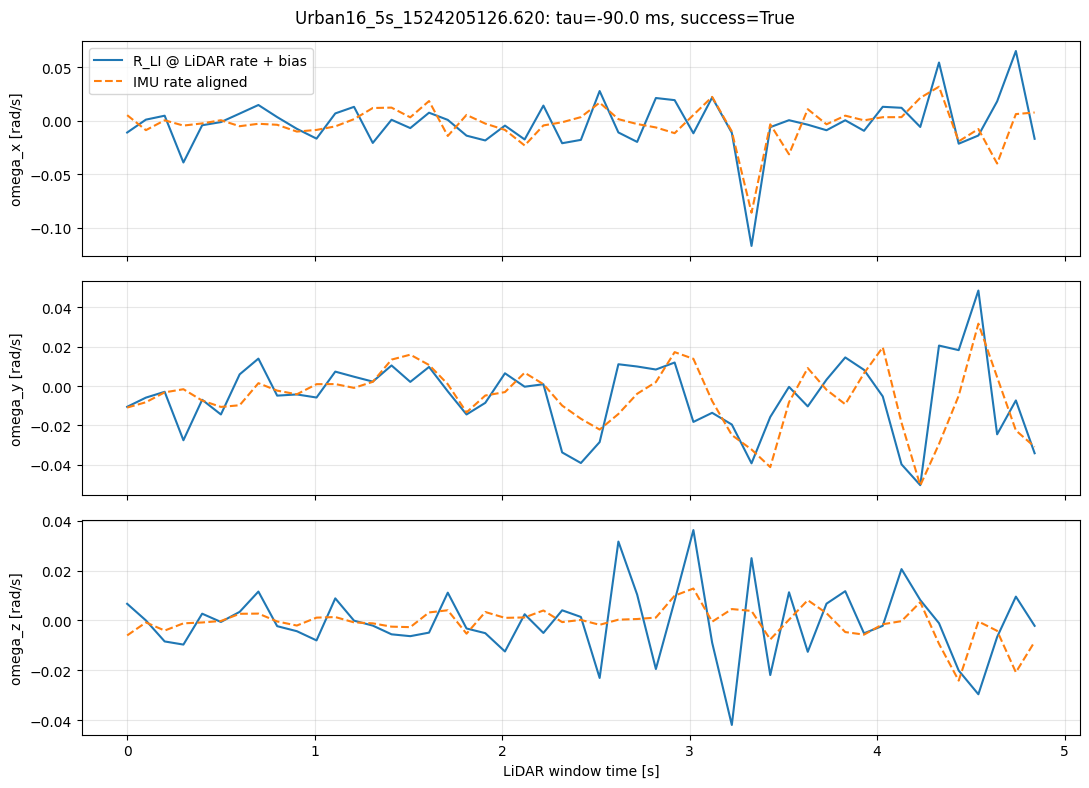

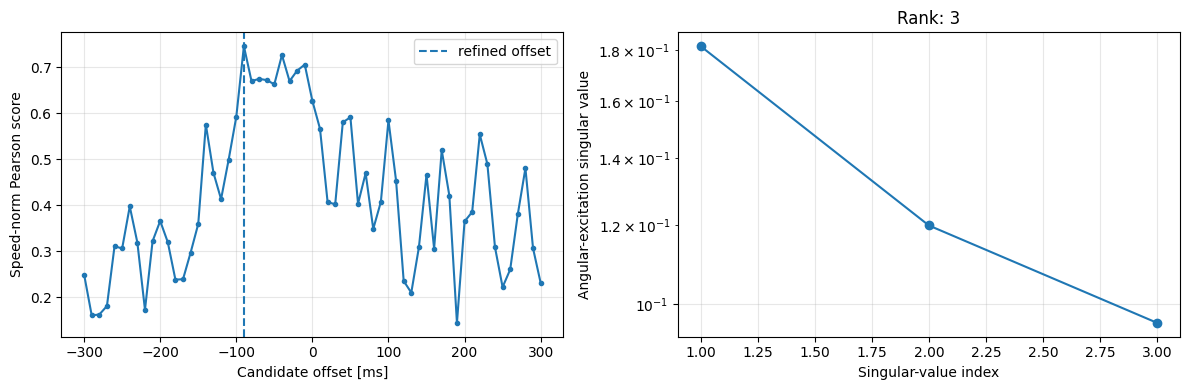

Plots saved to: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/outputs/plots/li_init


In [30]:
successful = [case for case in cases if case.name in fitted and fitted[case.name].success]
case = successful[0] if successful else cases[0]
result = fitted.get(case.name)
if result is None:
    print("First case failed; selecting first case with available numerical output")
    case = next((c for c in cases if c.name in fitted), None)
    result = fitted.get(case.name) if case is not None else None
if result is not None:
    motion = lidar_increments_to_motion(case.lidar)
    t = motion.t
    tau = result.time_offset
    R = result.R_LI
    query_t = t + tau
    valid = (query_t >= case.imu.t[0]) & (query_t <= case.imu.t[-1])
    omega_l_in_i = motion.ang_vel @ R.T + result.gyro_bias
    omega_i = np.column_stack([np.interp(query_t[valid], case.imu.t, case.imu.data_gyr[:, d]) for d in range(3)])

    fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
    for k in range(3):
        axes[k].plot(t[valid] - t[0], omega_l_in_i[valid, k], label="R_LI @ LiDAR rate + bias")
        axes[k].plot(t[valid] - t[0], omega_i[:, k], label="IMU rate aligned", linestyle="--")
        axes[k].set_ylabel(f"omega_{'xyz'[k]} [rad/s]")
        axes[k].grid(alpha=0.3)
    axes[0].legend()
    axes[-1].set_xlabel("LiDAR window time [s]")
    fig.suptitle(f"{case.name}: tau={tau*1e3:.1f} ms, success={result.success}")
    fig.tight_layout()
    fig.savefig(PLOTS_DIR / f"{case.name}_angular_alignment.png", dpi=150)
    if SHOW_PLOTS: plt.show()
    else: plt.close(fig)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    if result.temporal is not None:
        axes[0].plot(result.temporal.tested_offsets * 1000, result.temporal.scores, marker=".")
        axes[0].axvline(result.time_offset * 1000, linestyle="--", label="refined offset")
        axes[0].set_xlabel("Candidate offset [ms]")
        axes[0].set_ylabel("Speed-norm Pearson score")
        axes[0].legend()
    s = result.rotation.rotation_singular_values
    axes[1].semilogy(np.arange(1, len(s)+1), np.maximum(s, 1e-16), marker="o")
    axes[1].set_xlabel("Singular-value index")
    axes[1].set_ylabel("Angular-excitation singular value")
    axes[1].set_title(f"Rank: {result.rotation.rotation_rank}")
    for ax in axes: ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(PLOTS_DIR / f"{case.name}_temporal_observability.png", dpi=150)
    if SHOW_PLOTS: plt.show()
    else: plt.close(fig)
    print("Plots saved to:", PLOTS_DIR)
else:
    print("No case returned numerical output. Inspect results_df['error'].")

## Result analysis and optional NN comparison

Errors are computed only if independently verified references were set. Neural predictions are not loaded by default. When they become available, merge on the case `name` and ensure both methods use the **same five-second LiDAR window, clock convention, and IMU padding policy**. The classical method estimates an absolute `R_LI`; the NN may output a correction from a perturbed prior, so first convert the NN result to the same absolute convention.

In [31]:
print("Total windows:", len(results_df))
print("Successful:", int(results_df["success"].sum()), f"({results_df['success'].mean()*100:.1f}%)")
print("Median runtime [ms]:", round(float(results_df["elapsed_s"].median() * 1000), 2))
if reference is not None:
    good = results_df[results_df["success"]]
    print("Rotation median [deg]:", good["rotation_error_deg"].median())
    print("Rotation p90 [deg]:", good["rotation_error_deg"].quantile(0.9))
    if reference.time_offset is not None:
        print("Temporal offset median [ms]:", good["time_offset_error_ms"].median())

NN_RESULTS_CSV = None  # set Path to a CSV having columns `name`, `rotation_error_deg`
if NN_RESULTS_CSV is not None:
    nn_df = pd.read_csv(NN_RESULTS_CSV)
    assert {"name", "rotation_error_deg"}.issubset(nn_df.columns)
    paired = results_df.merge(nn_df[["name", "rotation_error_deg"]], on="name", how="inner", suffixes=("_li_init", "_nn"))
    display(paired[["name", "success", "rotation_error_deg_li_init", "rotation_error_deg_nn"]].head())
    print("Paired windows:", len(paired))
else:
    print("NN_RESULTS_CSV is None. CSV and plots are ready for a later paired comparison.")

Total windows: 21
Successful: 21 (100.0%)
Median runtime [ms]: 39.62
Rotation median [deg]: 12.598224653766803
Rotation p90 [deg]: 47.872670601204746
NN_RESULTS_CSV is None. CSV and plots are ready for a later paired comparison.


In [32]:
from dataclasses import replace
from scipy.spatial.transform import Rotation as SciRotation
from IPython.display import display
from baselines.li_init.estimator import LIInitCalibrator, lidar_increments_to_motion, solve_Rot_bias_gyro, xcorr_temporal_init
from baselines.li_init.benchmark import rotation_error_degrees
from baselines.li_init.adapters import slice_li_init_window

# Physical-window rollout settings, analogous to notebook 51.
APPENDIX_WINDOW_S = 5.0
APPENDIX_NUM_WINDOWS = 8
APPENDIX_STARTS = 2
APPENDIX_ANGLES_DEG = (0.0, 15.0, 45.0, 60.0, 90.0, 120.0, 150.0, 179.0)
APPENDIX_AXIS_SEEDS = 2                  # Increase to 3+ for stronger axis statistics.
APPENDIX_SEED = 234567
APPENDIX_MAX_TEMPORAL_CANDIDATES = 2     # Per-window coarse correlation peaks.
APPENDIX_SUCCESS_ANGLE_DEG = 5.0
APPENDIX_SHOW_PLOTS = bool(globals().get('SHOW_PLOTS', False))

required_names = ('cases', 'config', 'imu_full', 'lidar_full', 'PLOTS_DIR', 'OUTPUT_DIR')
missing = [name for name in required_names if name not in globals()]
if missing:
    raise RuntimeError(f'Run the earlier LI-Init notebook cells first; missing {missing}')

PLOTS_DIR = Path(PLOTS_DIR)
OUTPUT_DIR = Path(OUTPUT_DIR)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Exclude non-5-second cases; the ordered data are physical windows, not FM solver integration steps.
appendix_cases = sorted(
    [c for c in cases if c.window_duration_s is not None and abs(float(c.window_duration_s) - APPENDIX_WINDOW_S) < 1e-6],
    key=lambda c: float(c.lidar.t_start[0]),
)
if len(appendix_cases) < 2:
    raise ValueError('At least two 5-second BenchmarkCase windows are required')

# If the real rig reference is unknown, construct a longer-horizon reference for plotting ONLY.
if globals().get('reference') is not None:
    APPENDIX_R_REF = np.asarray(reference.R_LI, dtype=np.float64).copy()
    APPENDIX_REF_KIND = 'verified ground truth'
else:
    anchor_start = float(appendix_cases[0].lidar.t_start[0])
    anchor_end = float(appendix_cases[-1].lidar.t_end[-1])
    imu_anchor, lidar_anchor = slice_li_init_window(
        imu_full, lidar_full, anchor_start, anchor_end,
        imu_padding_s=float(globals().get('IMU_PADDING_S', 0.0)),
    )
    anchor_result = LIInitCalibrator(replace(config, estimate_translation=False)).fit(imu_anchor, lidar_anchor)
    if not anchor_result.rotation.success:
        raise RuntimeError(f'Long-horizon pseudo-reference is not observable: {anchor_result.rotation.message}')
    APPENDIX_R_REF = np.asarray(anchor_result.R_LI, dtype=np.float64).copy()
    APPENDIX_REF_KIND = f'long-horizon pseudo-reference ({anchor_end - anchor_start:.1f} s; NOT ground truth)'

print('Reference:', APPENDIX_REF_KIND)
print('Available 5-s windows:', len(appendix_cases))
print('Sweep:', APPENDIX_ANGLES_DEG, '| axes:', APPENDIX_AXIS_SEEDS)


Reference: verified ground truth
Available 5-s windows: 21
Sweep: (0.0, 15.0, 45.0, 60.0, 90.0, 120.0, 150.0, 179.0) | axes: 2


In [33]:
def appendix_start_positions(n: int, length: int, count: int) -> list[int]:
    """Choose evenly spaced full-length rollout starts without selecting future data."""
    last = n - length
    if last < 0:
        return []
    return sorted(set(np.linspace(0, last, min(count, last + 1)).round().astype(int).tolist()))


def appendix_axis(start: int, axis_id: int) -> np.ndarray:
    """Deterministic axes, identical across all compared initial angles."""
    rng = np.random.default_rng(APPENDIX_SEED + 1009 * start + 37 * axis_id)
    axis = rng.standard_normal(3)
    return axis / np.linalg.norm(axis)


def appendix_initial_rotation(angle_deg: float, axis: np.ndarray) -> np.ndarray:
    """Inject the desired initial calibration error, never perturb sensor measurements."""
    R = SciRotation.from_rotvec(np.deg2rad(angle_deg) * axis).as_matrix() @ APPENDIX_R_REF
    actual_deg = rotation_error_degrees(R, APPENDIX_R_REF)
    if abs(actual_deg - angle_deg) > 0.05:
        raise AssertionError((angle_deg, actual_deg))
    return R


appendix_starts = appendix_start_positions(len(appendix_cases), APPENDIX_NUM_WINDOWS, APPENDIX_STARTS)
if not appendix_starts:
    raise ValueError(f'Need {APPENDIX_NUM_WINDOWS} consecutive physical windows, found {len(appendix_cases)}')

# Verify the selected windows do not contain large physical time gaps.
appendix_sequences = {}
for start_index in appendix_starts:
    windows = appendix_cases[start_index:start_index + APPENDIX_NUM_WINDOWS]
    first_t = np.array([float(c.lidar.t_start[0]) for c in windows])
    if np.max(np.diff(first_t)) > 1.5 * APPENDIX_WINDOW_S:
        raise ValueError(f'Window sequence has a gap >1.5 window lengths starting at index {start_index}')
    appendix_sequences[start_index] = windows

# Keep the same raw odometry and IMU for every initial-angle experiment.
appendix_prepared = {}
for windows in appendix_sequences.values():
    for c in windows:
        if c.name in appendix_prepared:
            continue
        motion = lidar_increments_to_motion(c.lidar)
        temporal = xcorr_temporal_init(motion, c.imu, config) if config.estimate_time_offset else None
        if temporal is not None and not temporal.success:
            candidate_offsets = np.empty(0)
        elif temporal is not None:
            candidate_offsets = np.asarray(temporal.candidate_offsets[:APPENDIX_MAX_TEMPORAL_CANDIDATES], dtype=float)
        else:
            candidate_offsets = np.array([config.initial_time_offset], dtype=float)
        appendix_prepared[c.name] = (motion, candidate_offsets, temporal)

print('Selected starts:', appendix_starts, '| distinct physical windows:', len(appendix_prepared))
print('Windows with usable coarse synchronization:', sum(len(item[1]) > 0 for item in appendix_prepared.values()))


Selected starts: [0, 13] | distinct physical windows: 16
Windows with usable coarse synchronization: 16


In [34]:
def appendix_fit_warm_started(case, R_prior: np.ndarray, bias_prior: np.ndarray):
    """Run the existing local LI-Init joint solver from a supplied rotation prior.

    Coarse time candidates come only from cross-correlation of this window's data.
    This deliberately tests local solver sensitivity, unlike the standard
    prior-independent LIInitCalibrator.fit() interface.
    """
    motion, offsets, temporal = appendix_prepared[case.name]
    if offsets.size == 0:
        return None, 'coarse timing failed'

    attempts = []
    for offset in offsets:
        lo, hi = config.time_offset_bounds
        if config.estimate_time_offset and config.temporal_residual == 'taylor':
            lo = max(lo, float(offset) - config.temporal_local_half_width)
            hi = min(hi, float(offset) + config.temporal_local_half_width)
        if hi <= lo:
            continue
        candidate_config = replace(
            config,
            initial_time_offset=float(offset),
            time_offset_bounds=(float(lo), float(hi)),
            initial_gyro_bias=tuple(float(x) for x in bias_prior),
            estimate_translation=False,
        )
        try:
            result = solve_Rot_bias_gyro(motion, case.imu, candidate_config, initial_R_LI=R_prior)
            attempts.append(result)
        except (ValueError, RuntimeError, np.linalg.LinAlgError, FloatingPointError):
            continue

    if not attempts:
        return None, 'all timing candidates failed'
    # Prefer observable/converged results, then the lowest residual.
    best = min(attempts, key=lambda r: (not r.success, r.rms_residual))
    return best, str(best.message)


def appendix_run_rollout(start_index: int, axis_id: int, angle_deg: float) -> list[dict]:
    """Record the initial error and errors after successive *physical* windows."""
    windows = appendix_sequences[start_index]
    axis = appendix_axis(start_index, axis_id)
    R_prior = appendix_initial_rotation(angle_deg, axis)
    bias_prior = np.asarray(config.initial_gyro_bias, dtype=float).copy()
    rows = [dict(start=start_index, axis_id=axis_id, initial_deg=angle_deg, step=0,
                 elapsed_s=0.0, rotation_error_deg=rotation_error_degrees(R_prior, APPENDIX_R_REF),
                 update_success=np.nan, rms_radps=np.nan, time_offset_s=np.nan, nfev=0,
                 status='initial', case_name=None)]
    for step, c in enumerate(windows, 1):
        result, status = appendix_fit_warm_started(c, R_prior, bias_prior)
        success = result is not None and result.success
        if success:
            R_prior = np.asarray(result.R_LI).copy()
            bias_prior = np.asarray(result.gyro_bias).copy()
        # On a failure, retain the previous estimate; do not silently use a bad result.
        rows.append(dict(start=start_index, axis_id=axis_id, initial_deg=angle_deg, step=step,
                         elapsed_s=step * APPENDIX_WINDOW_S,
                         rotation_error_deg=rotation_error_degrees(R_prior, APPENDIX_R_REF),
                         update_success=bool(success),
                         rms_radps=float(result.rms_residual) if result is not None else np.nan,
                         time_offset_s=float(result.time_offset) if result is not None else np.nan,
                         nfev=int(result.nfev) if result is not None else 0,
                         status='accepted' if success else str(status), case_name=c.name))
    return rows


appendix_rollout_rows = []
for start_index in appendix_starts:
    for axis_id in range(APPENDIX_AXIS_SEEDS):
        for angle_deg in APPENDIX_ANGLES_DEG:
            appendix_rollout_rows.extend(appendix_run_rollout(start_index, axis_id, float(angle_deg)))
    print('Completed start', start_index)

appendix_rollout_df = pd.DataFrame(appendix_rollout_rows)
appendix_rollout_csv = OUTPUT_DIR / 'li_init_angle_warm_start_rollouts.csv'
appendix_rollout_df.to_csv(appendix_rollout_csv, index=False)
print('Saved:', appendix_rollout_csv, '| rows:', len(appendix_rollout_df))

# The standard, absolute-estimate cold-start baseline is independent of initial angle.
# Reuse fitted results from the main notebook; run any missing cases with the original estimator.
appendix_cold_rows = []
appendix_cache = globals().get('fitted', {})
for start_index, windows in appendix_sequences.items():
    for step, c in enumerate(windows, 1):
        try:
            cold = appendix_cache.get(c.name)
            if cold is None:
                cold = LIInitCalibrator(replace(config, estimate_translation=False)).fit(c.imu, c.lidar)
            appendix_cold_rows.append(dict(start=start_index, step=step,
                    elapsed_s=step * APPENDIX_WINDOW_S,
                    rotation_error_deg=rotation_error_degrees(cold.R_LI, APPENDIX_R_REF),
                    update_success=bool(cold.success)))
        except (ValueError, RuntimeError, np.linalg.LinAlgError, FloatingPointError):
            appendix_cold_rows.append(dict(start=start_index, step=step,
                    elapsed_s=step * APPENDIX_WINDOW_S,
                    rotation_error_deg=np.nan, update_success=False))
appendix_cold_df = pd.DataFrame(appendix_cold_rows)


Completed start 0
Completed start 13
Saved: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/outputs/li_init/li_init_angle_warm_start_rollouts.csv | rows: 288


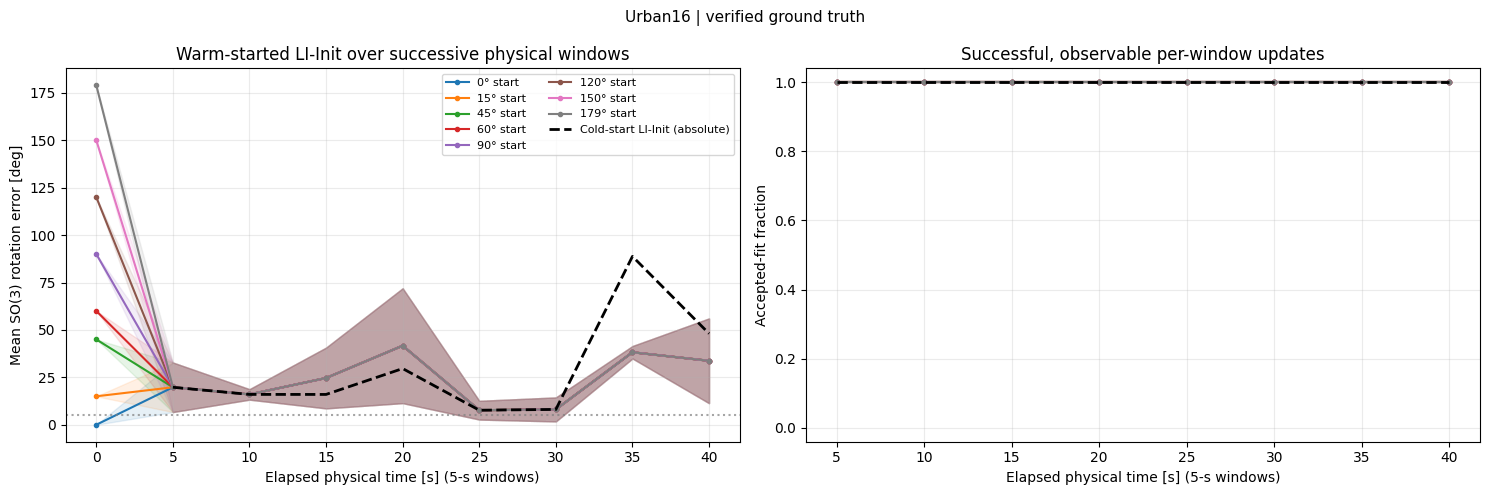

Saved: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/outputs/plots/li_init/li_init_warm_start_angle_sweep.png


,initial_deg,n,final_mean_deg,final_median_deg,final_p90_deg,success_under_5deg,median_improvement_deg
0,0.0,4,33.721,33.721,56.084,0.0,-33.721
1,15.0,4,33.721,33.722,56.086,0.0,-18.722
2,45.0,4,33.720,33.719,56.079,0.0,11.281
3,60.0,4,33.722,33.721,56.085,0.0,26.279
4,90.0,4,33.724,33.724,56.085,0.0,56.276
5,120.0,4,33.717,33.713,56.081,0.0,86.287
6,150.0,4,33.715,33.712,56.074,0.0,116.288
7,179.0,4,33.718,33.718,56.076,0.0,145.282


Saved: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/outputs/li_init/li_init_warm_start_endpoints.csv


In [35]:
appendix_summary = (
    appendix_rollout_df.groupby(['initial_deg', 'step'], as_index=False)
    .agg(n=('rotation_error_deg', 'size'),
         mean_deg=('rotation_error_deg', 'mean'),
         median_deg=('rotation_error_deg', 'median'),
         q10_deg=('rotation_error_deg', lambda x: x.quantile(.1)),
         q90_deg=('rotation_error_deg', lambda x: x.quantile(.9)),
         update_success_rate=('update_success', lambda x: float(pd.Series(x).dropna().mean()) if pd.Series(x).notna().any() else np.nan))
)
appendix_cold_summary = appendix_cold_df.groupby('step', as_index=False).agg(
    mean_deg=('rotation_error_deg', 'mean'),
    q10_deg=('rotation_error_deg', lambda x: x.quantile(.1)),
    q90_deg=('rotation_error_deg', lambda x: x.quantile(.9)),
    success_rate=('update_success', 'mean'),
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for angle_deg, g in appendix_summary.groupby('initial_deg'):
    g = g.sort_values('step')
    line, = axes[0].plot(g.elapsed_s if 'elapsed_s' in g else g.step * APPENDIX_WINDOW_S,
                         g.mean_deg, marker='o', markersize=3, label=f'{angle_deg:g}° start')
    axes[0].fill_between(g.step.to_numpy() * APPENDIX_WINDOW_S,
                         g.q10_deg.to_numpy(), g.q90_deg.to_numpy(),
                         alpha=0.11, color=line.get_color())
    axes[1].plot(g.step.to_numpy()[1:] * APPENDIX_WINDOW_S,
                 g.update_success_rate.to_numpy()[1:], marker='.', label=f'{angle_deg:g}° start')
axes[0].plot(appendix_cold_summary.step * APPENDIX_WINDOW_S,
             appendix_cold_summary.mean_deg, 'k--', linewidth=2, label='Cold-start LI-Init (absolute)')
axes[1].plot(appendix_cold_summary.step * APPENDIX_WINDOW_S,
             appendix_cold_summary.success_rate, 'k--', linewidth=2, label='Cold-start LI-Init (absolute)')
axes[0].axhline(APPENDIX_SUCCESS_ANGLE_DEG, color='gray', linestyle=':', alpha=.7)
axes[0].set(ylabel='Mean SO(3) rotation error [deg]',
            title='Warm-started LI-Init over successive physical windows')
axes[1].set(ylabel='Accepted-fit fraction', ylim=(-.04, 1.04),
            title='Successful, observable per-window updates')
for ax in axes:
    ax.set_xlabel('Elapsed physical time [s] (5-s windows)')
    ax.grid(alpha=.25)
axes[0].legend(fontsize=8, ncol=2)
fig.suptitle(f'{SEQUENCE_NAME if "SEQUENCE_NAME" in globals() else "LiDAR–IMU"} | {APPENDIX_REF_KIND}', fontsize=11)
fig.tight_layout()
appendix_plot_path = PLOTS_DIR / 'li_init_warm_start_angle_sweep.png'
fig.savefig(appendix_plot_path, dpi=180)
if APPENDIX_SHOW_PLOTS:
    plt.show()
else:
    plt.close(fig)
print('Saved:', appendix_plot_path)

endpoint_step = int(appendix_rollout_df.step.max())
appendix_endpoints = appendix_rollout_df[appendix_rollout_df.step == endpoint_step].groupby('initial_deg', as_index=False).agg(
    n=('rotation_error_deg', 'size'),
    final_mean_deg=('rotation_error_deg', 'mean'),
    final_median_deg=('rotation_error_deg', 'median'),
    final_p90_deg=('rotation_error_deg', lambda x: x.quantile(.9)),
    success_under_5deg=('rotation_error_deg', lambda x: float((x < APPENDIX_SUCCESS_ANGLE_DEG).mean())),
)
appendix_endpoints['median_improvement_deg'] = appendix_endpoints.initial_deg - appendix_endpoints.final_median_deg
display(appendix_endpoints.round(3))
appendix_endpoint_path = OUTPUT_DIR / 'li_init_warm_start_endpoints.csv'
appendix_endpoints.to_csv(appendix_endpoint_path, index=False)
print('Saved:', appendix_endpoint_path)


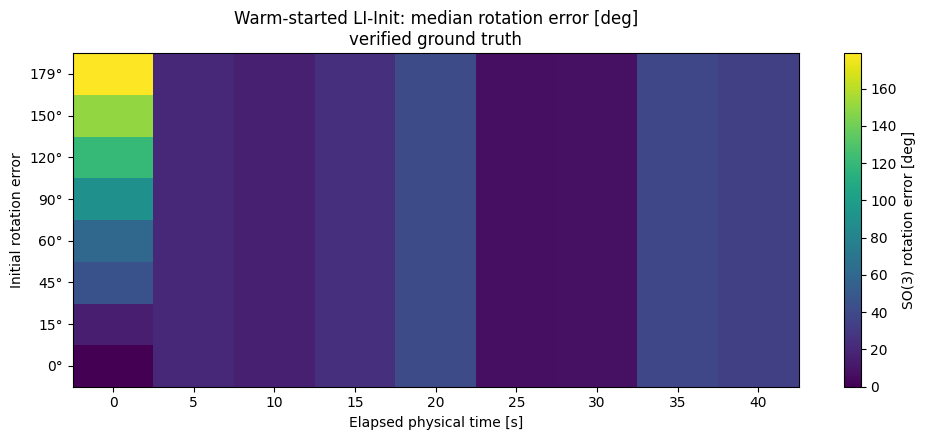

Saved: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/outputs/plots/li_init/li_init_warm_start_error_heatmap.png


In [36]:
pivot = appendix_summary.pivot(index='initial_deg', columns='step', values='median_deg').sort_index()
fig, ax = plt.subplots(figsize=(10, 4.5))
im = ax.imshow(pivot.to_numpy(), origin='lower', aspect='auto', cmap='viridis', vmin=0)
ax.set_xticks(np.arange(len(pivot.columns)), [f'{int(step * APPENDIX_WINDOW_S)}' for step in pivot.columns])
ax.set_yticks(np.arange(len(pivot.index)), [f'{angle:g}°' for angle in pivot.index])
ax.set(xlabel='Elapsed physical time [s]', ylabel='Initial rotation error',
       title=f'Warm-started LI-Init: median rotation error [deg]\n{APPENDIX_REF_KIND}')
fig.colorbar(im, ax=ax, label='SO(3) rotation error [deg]')
fig.tight_layout()
heatmap_path = PLOTS_DIR / 'li_init_warm_start_error_heatmap.png'
fig.savefig(heatmap_path, dpi=180)
if APPENDIX_SHOW_PLOTS:
    plt.show()
else:
    plt.close(fig)
print('Saved:', heatmap_path)


Interpreting these plots: The warm-start experiment measures the numerical optimizer's local capture range when seeded with different rotation errors and updated once per new physical window. The original full LIInitCalibrator.fit() uses a separate rotation-only/SVD initializer and should be evaluated as an absolute estimator, not as an iterative correction-to-go algorithm. Its results are identical across artificially chosen starting angles on the same window. Repeated warm-start updates are an additional baseline variant, not a direct reproduction of the published LI-Init initialization lifecycle.

For a fair comparison with your NN: use identical five-second LiDAR windows, disclose any extra IMU timing padding, count failed/underconstrained updates, and evaluate with independently verified extrinsics rather than the pseudo-reference. With a pseudo-reference, the figures are diagnostic only.

Matched starting positions: 12
Total calibration cases: 72
Window durations: (5.0, 10.0, 20.0, 30.0, 45.0, 60.0)


,window_duration_s,n_windows,n_success,success_rate,runtime_median_ms,rotation_median_deg,rotation_p90_deg,rotation_success_under_5deg,time_offset_median_ms
0,5.0,12.0,12.0,1.0,43.052,14.159,143.075,0.000,NaN
1,10.0,12.0,12.0,1.0,40.320,9.589,135.463,0.250,NaN
2,20.0,12.0,12.0,1.0,55.804,6.605,44.822,0.417,NaN
3,30.0,12.0,12.0,1.0,82.920,6.207,12.588,0.417,NaN
4,45.0,12.0,12.0,1.0,70.517,6.956,8.979,0.417,NaN
5,60.0,12.0,12.0,1.0,72.803,3.622,6.537,0.750,NaN


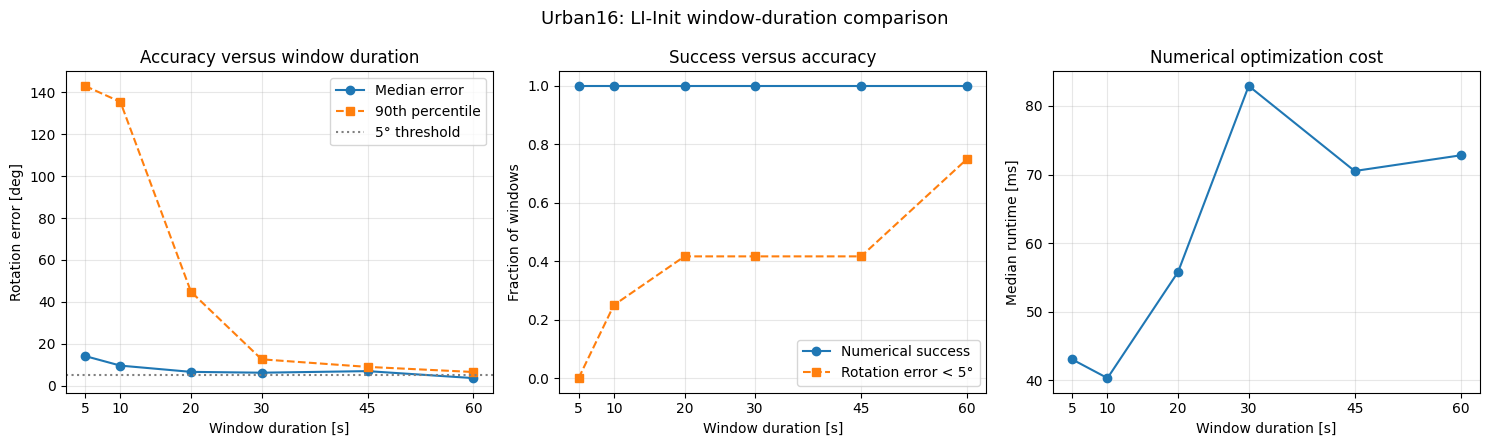

Saved plot: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/outputs/plots/li_init/Urban16_li_init_duration_comparison.png
Saved results: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/outputs/li_init/Urban16_li_init_long_windows.csv
Saved summary: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/outputs/li_init/Urban16_li_init_long_summary.csv


In [37]:

# ============================================================
# Appendix: LI-Init accuracy versus calibration window duration
# ============================================================

from dataclasses import replace
from baselines.li_init.adapters import slice_li_init_window
from baselines.li_init.benchmark import (
    BenchmarkCase,
    benchmark_li_init,
    summarize_li_init,
)

LONG_DURATIONS_S = (5.0, 10.0, 20.0, 30.0, 45.0, 60.0)
LONG_MAX_STARTS = 12
LONG_MAX_LIDAR_GAP_S = 0.75
LONG_IMU_PADDING_S = IMU_PADDING_S

if reference is None:
    raise RuntimeError("Provide ground-truth extrinsics before this experiment.")

# Find contiguous LiDAR odometry segments.
# Do not construct long windows across missing measurements.
lidar_starts = np.asarray(lidar_full.t_start)
lidar_ends = np.asarray(lidar_full.t_end)

gap_indices = np.flatnonzero(
    lidar_starts[1:] - lidar_ends[:-1] > LONG_MAX_LIDAR_GAP_S
) + 1

segment_starts = np.r_[0, gap_indices]
segment_stops = np.r_[gap_indices, len(lidar_starts)]

max_duration = max(LONG_DURATIONS_S)
candidate_anchors = []

for i0, i1 in zip(segment_starts, segment_stops):
    t0 = max(float(lidar_starts[i0]), float(imu_full.t[0]) + LONG_IMU_PADDING_S)
    t1 = min(float(lidar_ends[i1 - 1]), float(imu_full.t[-1]) - LONG_IMU_PADDING_S)

    if t1 - t0 >= max_duration - 1e-6:
        candidate_anchors.extend(
            np.arange(t0, t1 - max_duration + 1e-6, max_duration).tolist()
        )

candidate_anchors = np.asarray(sorted(set(candidate_anchors)), dtype=float)

if len(candidate_anchors) == 0:
    raise ValueError("No contiguous LiDAR segment supports a complete 60-second window.")

# Choose representative nonoverlapping 60-second starting positions.
indices = np.linspace(
    0, len(candidate_anchors) - 1,
    min(LONG_MAX_STARTS, len(candidate_anchors))
).round().astype(int)

selected_anchors = candidate_anchors[np.unique(indices)]

long_cases = []

for anchor_id, t0 in enumerate(selected_anchors):
    # Keep only anchors for which ALL durations can be evaluated.
    anchor_cases = []

    for duration in LONG_DURATIONS_S:
        try:
            imu_window, lidar_window = slice_li_init_window(
                imu_full,
                lidar_full,
                float(t0),
                float(t0 + duration),
                imu_padding_s=LONG_IMU_PADDING_S,
            )
        except ValueError as exc:
            print(f"Skipping anchor {anchor_id}: {exc}")
            break

        anchor_cases.append(
            BenchmarkCase(
                name=f"{SEQUENCE_NAME}_long_{anchor_id:03d}_{duration:g}s",
                sequence=SEQUENCE_NAME,
                imu=imu_window,
                lidar=lidar_window,
                reference=reference,
                window_duration_s=duration,
                imu_padding_s=LONG_IMU_PADDING_S,
            )
        )
    else:
        long_cases.extend(anchor_cases)

if not long_cases:
    raise ValueError("No matched multi-duration calibration cases could be constructed.")

print("Matched starting positions:", len(long_cases) // len(LONG_DURATIONS_S))
print("Total calibration cases:", len(long_cases))
print("Window durations:", LONG_DURATIONS_S)

# Use identical numerical settings for every duration.
long_config = replace(
    config,
    rotation_initialization="svd",
    filtering_enabled=False,
    estimate_translation=False,
)

long_results_df, long_fitted = benchmark_li_init(
    long_cases,
    long_config,
    return_results=True,
)

long_summary_df = summarize_li_init(long_results_df)
long_summary_df = long_summary_df.sort_values("window_duration_s")

display(long_summary_df.round(3))

# Save numerical results.
long_results_csv = OUTPUT_DIR / f"{SEQUENCE_NAME}_li_init_long_windows.csv"
long_summary_csv = OUTPUT_DIR / f"{SEQUENCE_NAME}_li_init_long_summary.csv"

long_results_df.to_csv(long_results_csv, index=False)
long_summary_df.to_csv(long_summary_csv, index=False)

# ============================================================
# Plots
# ============================================================

x = long_summary_df["window_duration_s"].to_numpy()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# (1) Calibration accuracy against rig reference.
axes[0].plot(
    x, long_summary_df["rotation_median_deg"],
    "o-", label="Median error"
)
axes[0].plot(
    x, long_summary_df["rotation_p90_deg"],
    "s--", label="90th percentile"
)
axes[0].axhline(5.0, linestyle=":", color="gray", label="5° threshold")
axes[0].set(
    xlabel="Window duration [s]",
    ylabel="Rotation error [deg]",
    title="Accuracy versus window duration",
)
axes[0].legend()

# (2) Numerical success and actual calibration accuracy.
axes[1].plot(
    x, long_summary_df["success_rate"],
    "o-", label="Numerical success"
)
axes[1].plot(
    x, long_summary_df["rotation_success_under_5deg"],
    "s--", label="Rotation error < 5°"
)
axes[1].set(
    xlabel="Window duration [s]",
    ylabel="Fraction of windows",
    ylim=(-0.05, 1.05),
    title="Success versus accuracy",
)
axes[1].legend()

# (3) Computation cost.
axes[2].plot(
    x, long_summary_df["runtime_median_ms"],
    "o-"
)
axes[2].set(
    xlabel="Window duration [s]",
    ylabel="Median runtime [ms]",
    title="Numerical optimization cost",
)

for ax in axes:
    ax.grid(alpha=0.3)
    ax.set_xticks(x)

fig.suptitle(
    f"{SEQUENCE_NAME}: LI-Init window-duration comparison",
    fontsize=13,
)
fig.tight_layout()

plot_path = PLOTS_DIR / f"{SEQUENCE_NAME}_li_init_duration_comparison.png"
fig.savefig(plot_path, dpi=180)

if SHOW_PLOTS:
    plt.show()
else:
    plt.close(fig)

print("Saved plot:", plot_path)
print("Saved results:", long_results_csv)
print("Saved summary:", long_summary_csv)


window_duration_s,5.0,10.0,20.0,30.0,45.0,60.0
anchor,,,,,,
0,32.83,9.78,3.71,3.28,3.97,3.65
1,121.41,161.52,48.57,12.97,14.31,14.28
2,153.50,15.73,1.42,6.69,6.42,6.41
3,6.86,2.60,2.58,2.60,2.29,1.00
4,6.00,1.56,3.73,4.75,7.93,4.77
5,15.66,2.75,6.79,8.19,7.82,3.14
6,6.27,6.14,6.42,5.72,3.29,3.60
7,145.48,77.46,93.54,21.38,7.49,6.55
8,16.51,141.91,11.10,7.41,7.70,1.51


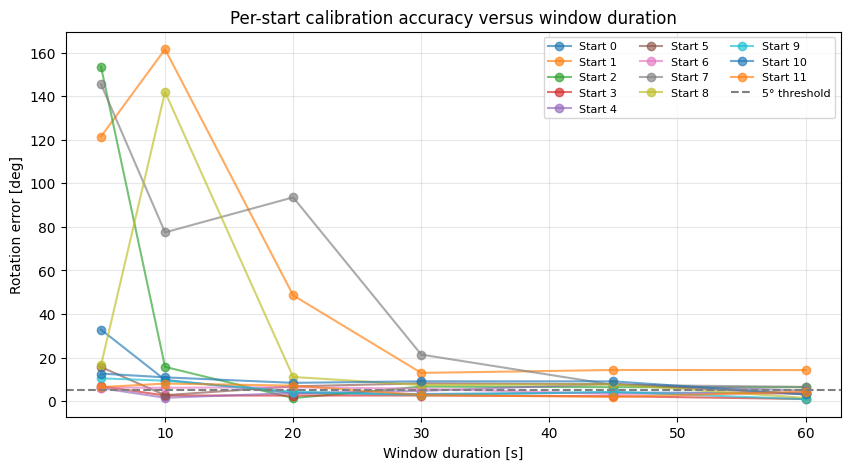

,name,rotation_error_deg,time_offset_s,rotation_rms_radps,rotation_rank,rotation_observable
12,Urban16_long_002_5s,153.501162,-0.27,0.013265,3,True
42,Urban16_long_007_5s,145.481699,-0.17,0.002987,3,True
6,Urban16_long_001_5s,121.414552,0.01,0.004479,3,True
0,Urban16_long_000_5s,32.831991,-0.09,0.016741,3,True
48,Urban16_long_008_5s,16.507198,-0.09,0.004082,3,True
30,Urban16_long_005_5s,15.656052,-0.01,0.019429,3,True
60,Urban16_long_010_5s,12.661842,0.00,0.026757,3,True
54,Urban16_long_009_5s,10.481420,-0.08,0.009290,3,True
18,Urban16_long_003_5s,6.859049,-0.05,0.027556,3,True
66,Urban16_long_011_5s,6.422785,0.00,0.022769,3,True


In [38]:

# Compare the same physical starting positions across durations.
diagnostics = long_results_df.copy()

diagnostics["anchor"] = diagnostics["name"].str.extract(
    r"_long_(\d+)_"
).astype(int)

error_table = diagnostics.pivot(
    index="anchor",
    columns="window_duration_s",
    values="rotation_error_deg",
)

display(error_table.round(2))

fig, ax = plt.subplots(figsize=(10, 5))

for anchor, row in error_table.iterrows():
    ax.plot(
        error_table.columns,
        row.values,
        marker="o",
        alpha=0.65,
        label=f"Start {anchor}",
    )

ax.axhline(5, color="gray", linestyle="--", label="5° threshold")
ax.set(
    xlabel="Window duration [s]",
    ylabel="Rotation error [deg]",
    title="Per-start calibration accuracy versus window duration",
)
ax.grid(alpha=0.3)
ax.legend(ncol=3, fontsize=8)
plt.show()

# Inspect the most problematic five-second cases.
worst = diagnostics[
    diagnostics["window_duration_s"] == 5
].sort_values("rotation_error_deg", ascending=False)

display(worst[[
    "name",
    "rotation_error_deg",
    "time_offset_s",
    "rotation_rms_radps",
    "rotation_rank",
    "rotation_observable",
]].head(12))
